# Introducrtion to Machine Learning: Assignment #4
## Submission date: 28\06\2026, 23:59.
### Topics:
- Bias vs Variance
- (Linear|Regularization|Kernel) Regression
- Cross validation
- Decision Trees
- Random forest

Submitted by:

 Rawa Abu salah  ID:325143634

 Reema khalaily  ID:214281479

**Assignment Instruction:**

· Submissions in pairs only.

· Try to keep the code as clean, concise, and short as possible

· If you wish to work in your IDE, you can, but you **must**,  insert the script back to the matching cells of the notebook and run the code. <br/>Only the notebook will be submitted in moodle (in `.ipynb` format).

· <font color='red'>Please write your answers to question in red</font>.

**Important:** All plots, results and outputs should be included in the notebook as the cells' outputs (run all cells and do not clear the output). <br/>

**Important:** Your submission must be entirely your own. Any attempts of plagiarism (including ChatGPT) will lead to grade 0 and disciplinary actions.


## Question 1 - Bias vs Variance
In this exercise, you will see the implication of bias-bariance bound on real problem.

**Note**: $L_D(h)$ will be measured here by the error obtained by a test dataset.

In [33]:
import numpy as np
import matplotlib.pyplot as plt

You are given a "PolyLearner" class - to generate data with different assumptions (agnostic / not), to fit it give a specific polynomial dgree, and visualize it. Read and understand it.

In [34]:
#@title PolyLearner definition

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LogisticRegression

class PolyLearner:
    """
    Generates a synthetic classification problem based on a random
    polynomial decision boundary and learns it using polynomial
    logistic regression.

    Intended for bias-variance demonstrations.
    """

    def __init__(
        self,
        true_degree=20,
        noise_rate=0.15,
        agnostic=False,
        random_state=None
    ):
        self.true_degree = true_degree
        self.noise_rate = noise_rate
        self.agnostic = agnostic

        self.rng = np.random.default_rng(random_state)

        self.true_weights = None
        self.model = None

    # ---------------------------------------------------------
    # Data generation
    # ---------------------------------------------------------

    def generate(self, n_samples):
        """
        Generate synthetic data.

        Returns
        -------
        X : shape (n_samples, 2)
        y : {-1, +1}
        """

        X = self.rng.uniform(-1, 1, size=(n_samples, 2))

        if self.agnostic:
            y = self.rng.choice([-1, 1], size=n_samples)
            return X, y

        poly = PolynomialFeatures(
            degree=self.true_degree,
            include_bias=True
        )

        Phi = poly.fit_transform(X)

        if self.true_weights is None:
            w = self.rng.normal(0, 1, Phi.shape[1])
            w /= np.linalg.norm(w)
            self.true_weights = w

        f = Phi @ self.true_weights

        y = np.where(f > 0, 1, -1)

        flip_mask = (
            self.rng.random(n_samples)
            < self.noise_rate
        )

        y[flip_mask] *= -1

        return X, y

    # ---------------------------------------------------------
    # Learning
    # ---------------------------------------------------------

    def fit(
        self,
        X,
        y,
        degree,
        C=1e12
    ):
        """
        Fit polynomial logistic regression.
        """

        self.model = Pipeline([
            ("poly", PolynomialFeatures(degree=degree)),
            ("clf", LogisticRegression(C=C, max_iter=50000))
        ])

        self.model.fit(X, y)

        return self

    # ---------------------------------------------------------
    # Evaluation
    # ---------------------------------------------------------

    def score(self, X, y):
        return self.model.score(X, y)

    # ---------------------------------------------------------
    # Visualization
    # ---------------------------------------------------------

    def plot_boundary(
        self,
        X,
        y,
        resolution=300
    ):
        """
        Plot learned decision boundary.
        """

        if self.model is None:
            raise RuntimeError(
                "Call fit() before plotting."
            )

        x_min = X[:, 0].min() - 0.2
        x_max = X[:, 0].max() + 0.2

        y_min = X[:, 1].min() - 0.2
        y_max = X[:, 1].max() + 0.2

        xx, yy = np.meshgrid(
            np.linspace(x_min, x_max, resolution),
            np.linspace(y_min, y_max, resolution)
        )

        grid = np.c_[
            xx.ravel(),
            yy.ravel()
        ]

        probs = (
            self.model
            .predict_proba(grid)[:, 1]
            .reshape(xx.shape)
        )

        plt.figure(figsize=(8, 8))

        plt.contourf(
            xx,
            yy,
            probs,
            levels=np.linspace(0, 1, 20),
            alpha=0.4
        )

        plt.contour(
            xx,
            yy,
            probs,
            levels=[0.5],
            linewidths=3
        )

        plt.scatter(
            X[y == -1, 0],
            X[y == -1, 1],
            label="Class -1"
        )

        plt.scatter(
            X[y == 1, 0],
            X[y == 1, 1],
            marker="x",
            label="Class +1"
        )

        poly_degree = (
            self.model.named_steps["poly"]
            .degree
        )

        plt.title(
            f"Polynomial degree {poly_degree}"
        )

        plt.legend()
        plt.show()

Basic visualization. Make sure to undersand it.

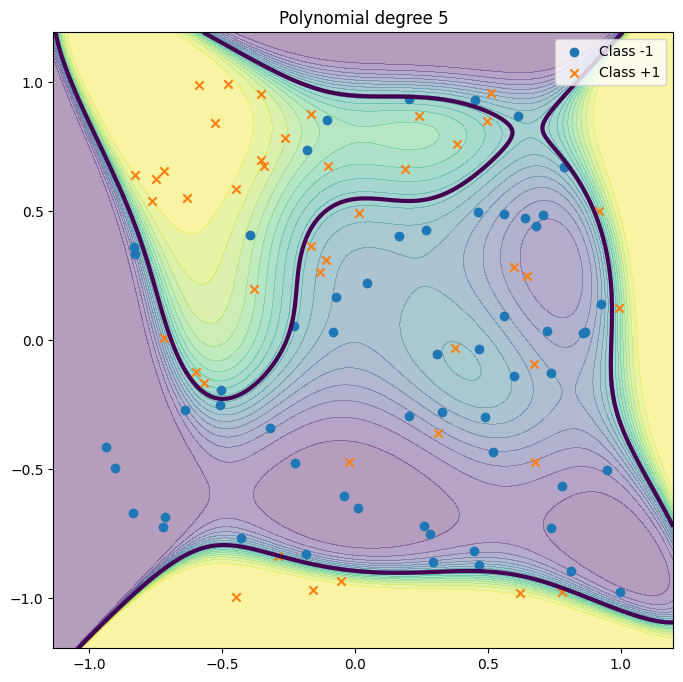

In [ ]:
obj = PolyLearner(agnostic=False)
X,y = obj.generate(100)
obj.fit(X, y, degree=5)
obj.plot_boundary(X,y)

Tasks:
1. Generate 400 samples. Take the first 300 for training, last 100 for test.
2. Print a plot showing the <u>error</u> of the model both on train and test, as a function of d, from 1 to 25.
3. Repeat the above for an agnostic dataset. make sure to put both graphs next to each other, with corresponding titles.<!--Actually, make it d from 1 to 100-->

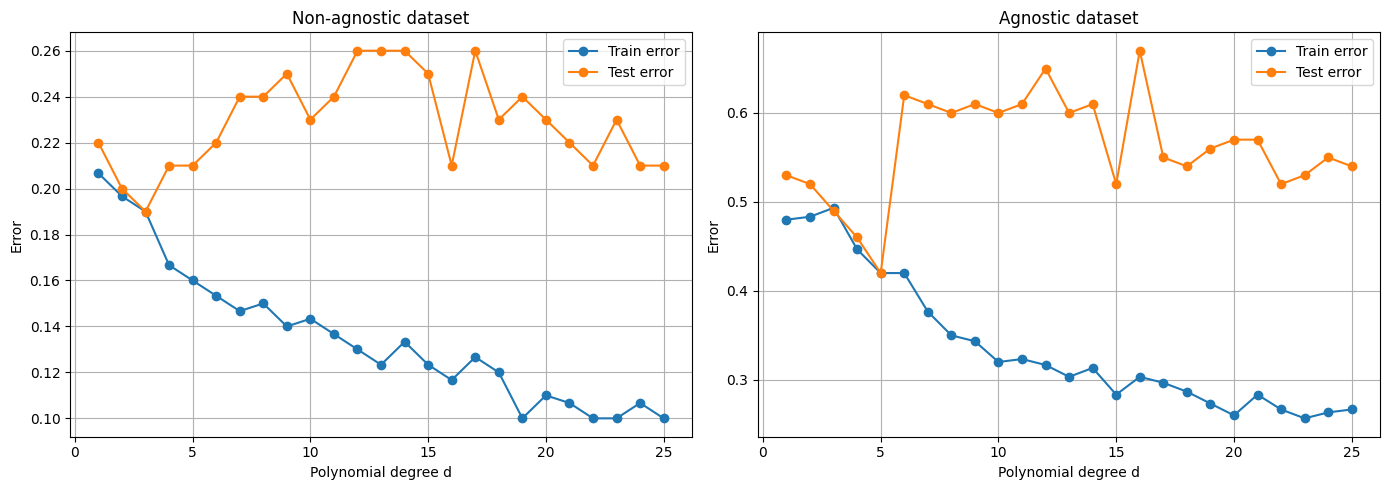

In [35]:
import numpy as np
import matplotlib.pyplot as plt

degrees = range(1, 26)

def compute_errors(agnostic):
    obj = PolyLearner(agnostic=agnostic, random_state=42)

    X, y = obj.generate(400)

    X_train = X[:300]
    y_train = y[:300]

    X_test = X[300:]
    y_test = y[300:]

    train_errors = []
    test_errors = []

    for d in degrees:
        obj.fit(X_train, y_train, degree=d)

        train_acc = obj.score(X_train, y_train)
        test_acc = obj.score(X_test, y_test)

        train_errors.append(1 - train_acc)
        test_errors.append(1 - test_acc)

    return train_errors, test_errors


train_errors_regular, test_errors_regular = compute_errors(agnostic=False)
train_errors_agnostic, test_errors_agnostic = compute_errors(agnostic=True)


plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(degrees, train_errors_regular, marker='o', label='Train error')
plt.plot(degrees, test_errors_regular, marker='o', label='Test error')
plt.xlabel('Polynomial degree d')
plt.ylabel('Error')
plt.title('Non-agnostic dataset')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(degrees, train_errors_agnostic, marker='o', label='Train error')
plt.plot(degrees, test_errors_agnostic, marker='o', label='Test error')
plt.xlabel('Polynomial degree d')
plt.ylabel('Error')
plt.title('Agnostic dataset')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Within each setting, explain the results you got. What happens with a lower degree, higher degree. Why does this happen? <br/>
In your answer, make sure to relate to the $m=400$ as well.


<font color='red'> 1.non agnostic dataset: according to what we have learned : we assumed that f in our hypothesis class.
when the polynom's dgree is low the model is very simple and can't describe the desicion rule well , therefore the bias is very high which means that the trainig error and test error is high , when the polynom  dgree's increase the model can describe the desicion rule better so the bias will decrease and the training error is decreasing ,the test error in the beginnig is decreasing because the model trying to learn the real hypothesis but when the dgree is getting higher the test error will change : in the test we have data set that we didnt see before so it is possible that a some higher dgree have more errors than a model with low dgree because the model starts fitting the noise (high variance / overfitting)

<font color='red'> 2.agnostic dataset :we dont have a deterministic function in our hypothesis class so when the polynom dgree is increasing the test error is always about 0.50 because there is no real model that can be generlaized in new data ,so the test error in agnostic dataset is larger than non agnostic dataset
,the training error in agnostic dataset behave nearly like the training error in non agnostic dataset .
we have m=400 that can be affect the results because the number of data is limited ,so when the polynom's degree increases the moel got more complex and we have limited samples, leading to a high variance ,therfore the test error is unstable so as we see the test error keep increasin and decreasing all the time ,so if the data is larger we would have a more stable test error


It is a well known fact (from the lectures) that given the family of hypotheses $h(x)=\text{sign}(w^\top x)$, $VC(\mathcal{H})=d$, where d is #of features.

When using PolyLearner, the classification is done by $h(x)=\text{sign}(\phi(x))$, where $\phi(x)$ creates a feature map using monoms with degree at most $d$, meaning $x_1^ax_2^b$ such that $a+b\leq d$.
1. Using polynoms of d=20 and we have 2 features, how many monoms are involved? Meaning - what is the dimension of $\phi(x)$?
2. Conclude what is $VC(\mathcal{H})$.
<font color='red'>Write here your answers and explain them.</font>

<font color='red'> we notice if d=2 then we have 6 features : 1,x1,x2,x1^2,x2^2,x1x2.
the equation is=1+2+3=6
so we sum from 1 to k+1
if d=20 so we got sum=1+....+21=231.

so we have 231 features when the dgree is 20.
2. according to what we have learned if we have a linear classifir h with d features , the VCdim(h)=d , therefore according to the sulotion to question 1
VCdim(h)=231 </font>

Now, for both settings (realizable and agnostic) take d=6 and $\epsilon=0.05$, $\delta=0.01$.
For 2k times, take $m$ samples, according to the fomulas learned in class. Since they are given by $m=\Theta(..)$, use 1 as your leading constant.

Print the rate of getting error $>\epsilon$. <!--Actually, take d=7, epsilon=0.01-->

In [36]:
from tqdm import tqdm

d = 6
vc = int((d + 1) * (d + 2) / 2)
epsilon = 0.05
delta = 0.01
k = 2000

m1 = int((vc * np.log(1 / epsilon) + np.log(1 / delta)) / epsilon)

m2 = int((vc + np.log(1 / delta)) / (epsilon ** 2))

obj1 = PolyLearner(agnostic=False)
obj2 = PolyLearner(agnostic=True)

X_test1, y_test1 = obj1.generate(1000)
X_test2, y_test2 = obj2.generate(1000)

rate1 = 0
rate2 = 0

# Implement here
for _ in tqdm(range(k)):
    X_train1, y_train1 = obj1.generate(m1)
    obj1.fit(X_train1, y_train1, degree=d)
    error1 = 1 - obj1.score(X_test1, y_test1)

    if error1 > epsilon:
        rate1 += 1

    X_train2, y_train2 = obj2.generate(m2)
    obj2.fit(X_train2, y_train2, degree=d)
    error2 = 1 - obj2.score(X_test2, y_test2)

    if error2 > epsilon:
        rate2 += 1
print(f"VC(H): {vc}")
print(f"m for realizable setting: {m1}")
print(f"m for agnostic setting: {m2}")
print(f"Realizable Dataset: {rate1 / k}")
print(f"Agnostic Dataset: {rate2 / k}")

100%|██████████| 2000/2000 [06:26<00:00,  5.18it/s]

VC(H): 28
m for realizable setting: 1769
m for agnostic setting: 13042
Realizable Dataset: 1.0
Agnostic Dataset: 1.0


Answer the following questions:
1. Why did PAC fail?
2. Why did Agnotisc PAC fail?
<font color='red'>Write here your answers and explain them.</font>
<font color='red'>
PAC failed because the proior assumpation were violated , we assumed the the degree of the polynom is 20 but we used d=6 , so the target function that the model trying to find is not necessarliy insie the hypothesis class
so the error is always bigger than epsilon if the target function is not inside the hypothesis class.
in addition, the generated data contains 15% label noise, so the data is not perfectly realizable. Therefore, the error cannot be guaranteed to be smaller than epsilon

2.aggnostic PAC failed because there is no detrministic functicon y=f(x) inside the hypothesis class therefore the best possible classifier has error
</font>

To sum up, take d=10 for both settings.
Tasks:
1. Generate m samples. Generate saperately 1000 samples for the test set.
2. Print a plot showing the <u>error</u> of the model both on train and test, as a function of m.<!--Generate 1057 samples-->

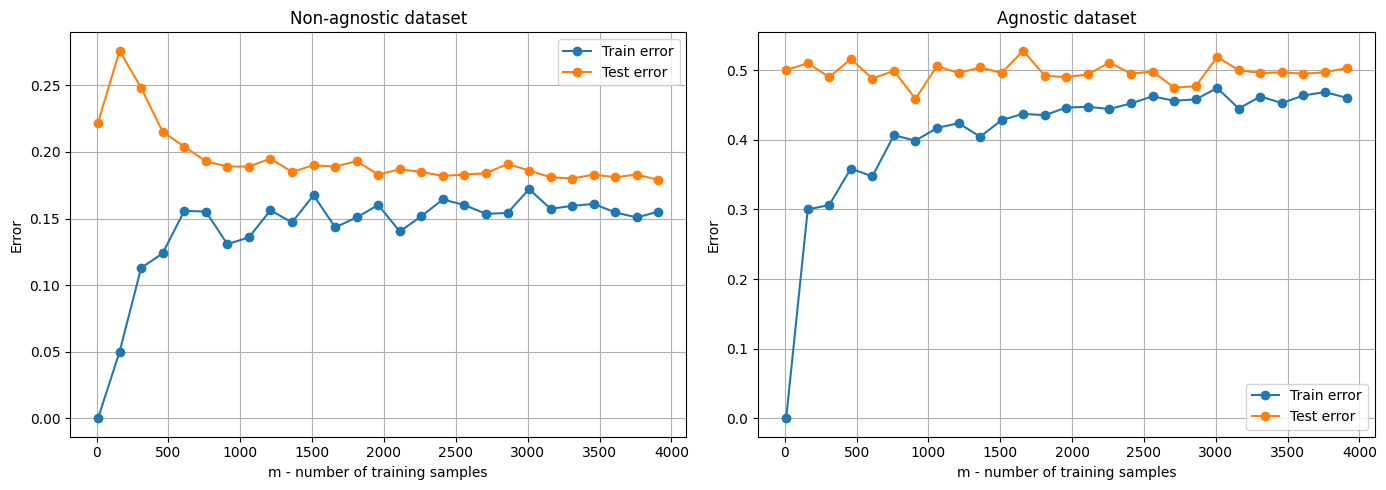

In [ ]:
d = 10
obj1 = PolyLearner(agnostic=False)
obj2 = PolyLearner(agnostic=True)

ms = np.arange(10, 4000, 150)
def errors_as_function_of_m(obj, title):
    X_test, y_test = obj.generate(1000)

    train_errors = []
    test_errors = []

    for m in ms:
        X_train, y_train = obj.generate(m)

        obj.fit(X_train, y_train, degree=d)

        train_error = 1 - obj.score(X_train, y_train)
        test_error = 1 - obj.score(X_test, y_test)

        train_errors.append(train_error)
        test_errors.append(test_error)

    plt.plot(ms, train_errors, marker='o', label='Train error')
    plt.plot(ms, test_errors, marker='o', label='Test error')
    plt.xlabel('m - number of training samples')
    plt.ylabel('Error')
    plt.title(title)
    plt.legend()
    plt.grid(True)


plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
errors_as_function_of_m(obj1, 'Non-agnostic dataset')

plt.subplot(1, 2, 2)
errors_as_function_of_m(obj2, 'Agnostic dataset')

plt.tight_layout()
plt.show()

Within each setting, explain the results you got. What happens at a lower or higher number of samples. Why does this happen? In your answer, make sure relate to the $d=10$ as well. In particular, why does agnostic error is $\approx$0.5?



<font color='red'>
1. on non agnostic dataset , when m is small the train error is 0 because the model can fit to a few samples, but the test error is high because we use a polynomial of degree d=10, the model is relatively complex. therefore, when m is small, it can easily overfit the training data, so in the test we will  see in a high probability a new data that we havent see before (overfitting).
when the value of m is getting larger the training error and test error is more stable nearly in 0.15 , which means more samples help the model to generalize well .

2. on agnostic dataset ,the test error is always ≈0.5 for every m ,because the test error effected by agnostic model , as m increaes the train error is getting close to the test error  because with more training examples, it becomes harder for the model to memorize random noise.

</font>


## Question 2 - Regression
You are requested to predict energy efficiency based on building attributes, such as wall area and glazing area.
The dataset consists of 8 continious features and **Two** outputs - Heat & Cool loadings.
You can read more about the dataset <a href='https://archive.ics.uci.edu/dataset/242/energy+efficiency'>here</a>.

In [1]:
# import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso

Load data from https://sharon.srworkspace.com/ml/datasets/hw3/ENB2012_data.csv

In [2]:
df = pd.read_csv('https://sharon.srworkspace.com/ml/datasets/hw3/ENB2012_data.csv')
df.head(3)

,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33


Divide the data into 85% train and 15% test with random_state=21.



In [3]:
from sklearn.model_selection import train_test_split

X = df.iloc[:, :8] #the features
y = df.iloc[:, 8:] # the output (heat&cool)

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.15,random_state=21)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(652, 8)
(116, 8)
(652, 2)
(116, 2)


Define sklearn's linear regression, fit the train and save both train and test MSEs (by appending to results['Linear']). <br/>
DO NOT use "score" method of sklearn - we didn't learn about it and it does not measure MSE.

In [4]:
results = {'Linear': [], 'Ridge': [], 'Lasso': []}

from sklearn.metrics import mean_squared_error

model = LinearRegression()

model.fit(X_train, y_train)

y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

train_mse = mean_squared_error(y_train, y_pred_train)
test_mse = mean_squared_error(y_test, y_pred_test)

results['Linear'].append((train_mse, test_mse))

print("Train MSE:", train_mse)
print("Test MSE:", test_mse)

Train MSE: 9.629313118937043
Test MSE: 7.6836546007716535


Show the correlation matrix of the train data. What is the conclusion? What should we do?

<font color='red'> as we see the correlation matrix that we got shows that there are feautures highly corrleated like X1  and X2 ...
therfore the regrission might be unstable ,we need to use regulazation to solve this problem </font>

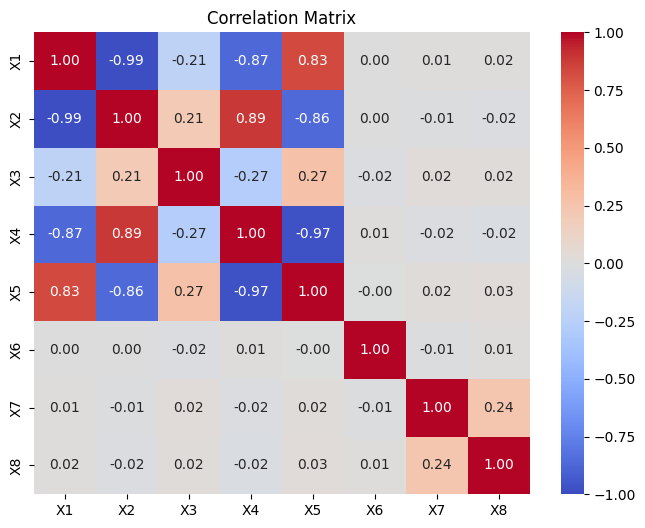

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

corr_matrix = X_train.corr()

plt.figure(figsize=(8,6))

sns.heatmap( corr_matrix, annot=True, fmt=".2f",cmap="coolwarm", vmin=-1, vmax=1)

plt.title("Correlation Matrix")
plt.show()

For both ridge and lasso, tune the best $\lambda$ using cross_val_score, using 10 splits and scoring='neg_mean_squared_error'.
- For ridge, $\lambda\in \text{np.logspace}(-2, 0, 50)$.
- For lasso, $\lambda\in \text{np.logspace}(-4, -2, 50)$.

$\text{np.logspace}$ is like a range, but with base 10. For example, $\text{np.logspace}(-2, 1, 50)$ goes from $10^{-2}$ to $10^0$.

Make sure to print a graph showing the test MSE of all $\lambda$ in subplot(1,2).

best ridge lambda = 0.01
best ridge mse = 9.850926865940625
best lasso lambda = 0.0001
best lasso mse = 9.843088361400282


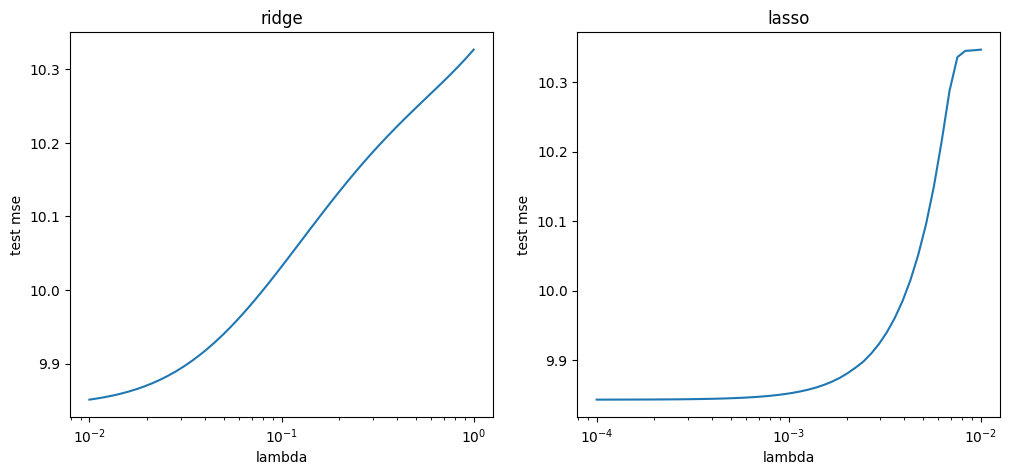

In [6]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import Ridge, Lasso
from sklearn.multioutput import MultiOutputRegressor

ridge_lambdas = np.logspace(-2, 0, 50)
lasso_lambdas = np.logspace(-4, -2, 50)

ridge_mse = []
lasso_mse = []

for lam in ridge_lambdas:
    model = Ridge(alpha=lam)
    scores = cross_val_score(model, X_train, y_train, cv=10, scoring='neg_mean_squared_error')
    ridge_mse.append(-scores.mean())

for lam in lasso_lambdas:
    model = MultiOutputRegressor(Lasso(alpha=lam, max_iter=10000))
    scores = cross_val_score(model, X_train, y_train, cv=10, scoring='neg_mean_squared_error')
    lasso_mse.append(-scores.mean())

best_ridge_lambda = ridge_lambdas[np.argmin(ridge_mse)]
best_lasso_lambda = lasso_lambdas[np.argmin(lasso_mse)]

print("best ridge lambda =", best_ridge_lambda)
print("best ridge mse =", min(ridge_mse))
print("best lasso lambda =", best_lasso_lambda)
print("best lasso mse =", min(lasso_mse))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(ridge_lambdas, ridge_mse)
plt.xscale('log')
plt.xlabel('lambda')
plt.ylabel('test mse')
plt.title('ridge')

plt.subplot(1, 2, 2)
plt.plot(lasso_lambdas, lasso_mse)
plt.xscale('log')
plt.xlabel('lambda')
plt.ylabel('test mse')
plt.title('lasso')

plt.show()

Repeat the process done above with linear regression and save both train and test MSEs to the correct column.

Don't forget to preprocess the data as learned.

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from sklearn.multioutput import MultiOutputRegressor

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

ridge = Ridge(alpha=best_ridge_lambda)
ridge.fit(X_train_scaled, y_train)

ridge_train_pred = ridge.predict(X_train_scaled)
ridge_test_pred = ridge.predict(X_test_scaled)

ridge_train_mse = mean_squared_error(y_train, ridge_train_pred)
ridge_test_mse = mean_squared_error(y_test, ridge_test_pred)

results['Ridge'].append((ridge_train_mse, ridge_test_mse))

lasso = MultiOutputRegressor(Lasso(alpha=best_lasso_lambda, max_iter=10000))
lasso.fit(X_train_scaled, y_train)

lasso_train_pred = lasso.predict(X_train_scaled)
lasso_test_pred = lasso.predict(X_test_scaled)

lasso_train_mse = mean_squared_error(y_train, lasso_train_pred)
lasso_test_mse = mean_squared_error(y_test, lasso_test_pred)

results['Lasso'].append((lasso_train_mse, lasso_test_mse))

print("ridge train mse:", ridge_train_mse)
print("ridge test mse:", ridge_test_mse)

print("lasso train mse:", lasso_train_mse)
print("lasso test mse:", lasso_test_mse)

ridge train mse: 9.629315821758041
ridge test mse: 7.683415194625621
lasso train mse: 9.62931607093129
lasso test mse: 7.683235141038081


Print results from all three models.
1. Explain the results and determine which model was be best.
2. Why did this happen?
3. What might be the cause to the values for searching given above? Why are the search scales different?

<font color='red'>Write your answers here and explain them</font>

<font color='red'>
 1.the three models give nearly the same results, we can choose lasso as the best model because it has the lowest test error </font>

<font color='red'> 2.this happened because the regulazation values that we chose are very small , therfore the regulization would not affect the model and  the results stay close to the result before the regulazation </font>

<font color='red'>3. the search ranges differ from each other because Ridge and Lasso don't penalize on the same way , ridge uses norm 2 to regularize so the cofficients shrink gradually , Lasso uses norm 1 which can shrink some coefficients to zero.
 therefore, lasso is usually more sensitive to the regularization so we search smaller alpha values for lasso
 </font>


In [8]:
df = pd.DataFrame(results, columns=['Linear', 'Ridge', 'Lasso'], index=['train', 'test'])
print(df)

                                        Linear  \
train  (9.629313118937043, 7.6836546007716535)   
test   (9.629313118937043, 7.6836546007716535)   

                                        Ridge  \
train  (9.629315821758041, 7.683415194625621)   
test   (9.629315821758041, 7.683415194625621)   

                                       Lasso  
train  (9.62931607093129, 7.683235141038081)  
test   (9.62931607093129, 7.683235141038081)  


For both ridge and lasso, repeat the fitting algorithm but this time, plot a graph showing the values of w1,...,w8 as a function of the $\lambda$ search space. Make sure to generate a corresponding titles for both graphs and put them side by side.

Explain the results you got for each setting. What happened as $\lambda$ got larger? Who got 0 first? Why is that?

<font color='red'>

as lamda becomes larger, in ridge, the coefficients become smaller little by little, but they usually stay different from zero. in lasso, some coefficients become exactly zero . this happens because lasso uses L1 regularization(norm 1), which can remove features completely, while ridge uses L2 regularization(norm2), which only reduces the coefficients without removing them</font>

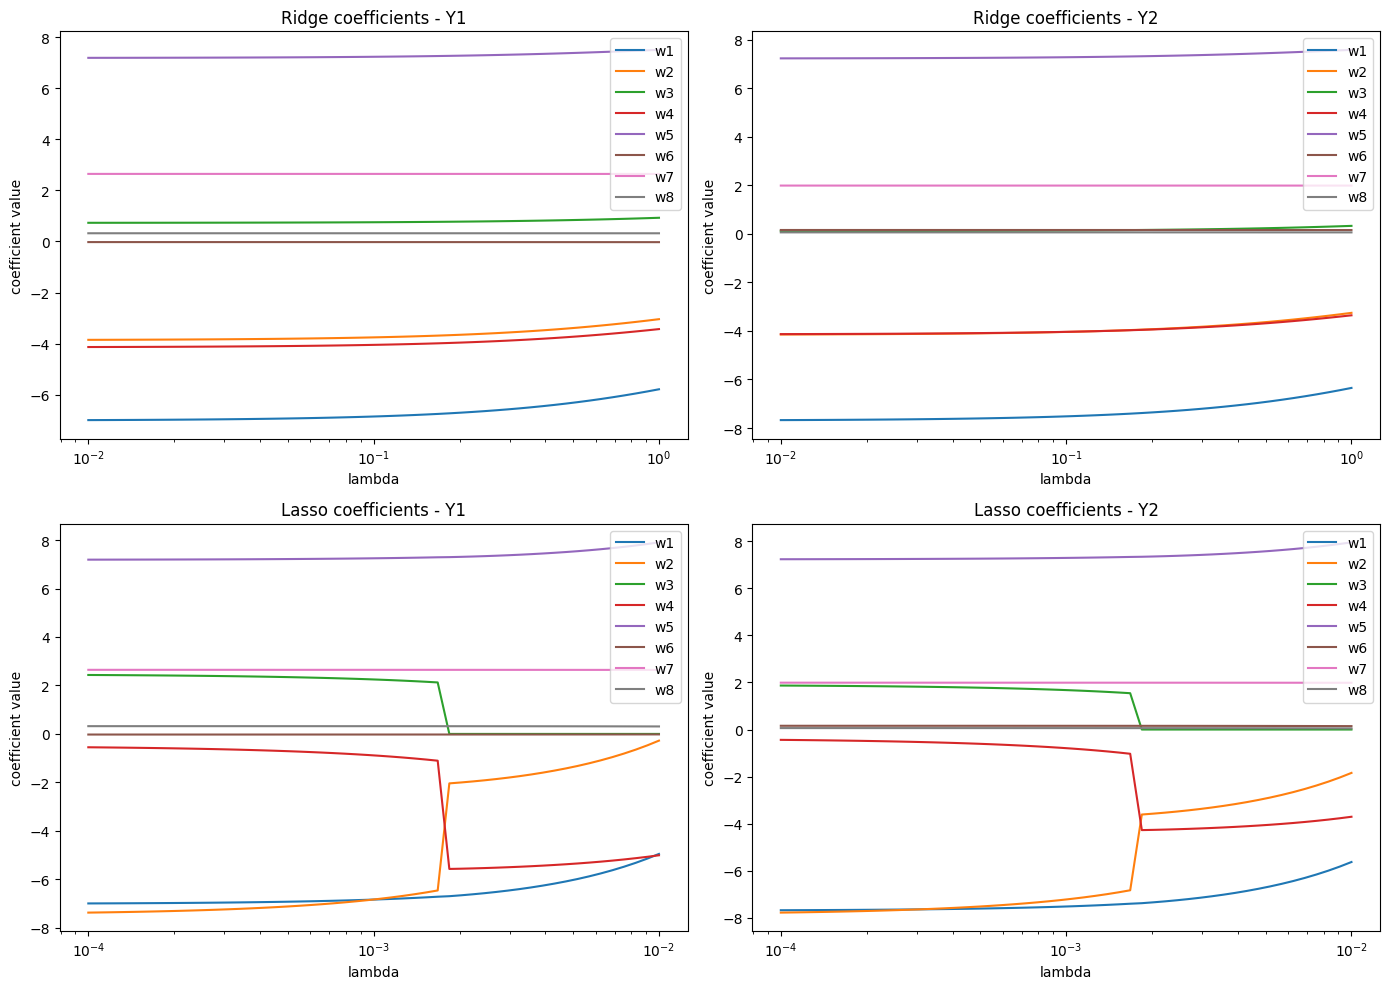

In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.multioutput import MultiOutputRegressor

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

ridge_lambdas = np.logspace(-2, 0, 50)
lasso_lambdas = np.logspace(-4, -2, 50)

ridge_weights_y1 = []
ridge_weights_y2 = []

lasso_weights_y1 = []
lasso_weights_y2 = []

for lam in ridge_lambdas:
    ridge = Ridge(alpha=lam)
    ridge.fit(X_train_scaled, y_train)

    ridge_weights_y1.append(ridge.coef_[0])
    ridge_weights_y2.append(ridge.coef_[1])

for lam in lasso_lambdas:
    lasso = MultiOutputRegressor(Lasso(alpha=lam, max_iter=10000))
    lasso.fit(X_train_scaled, y_train)

    lasso_weights_y1.append(lasso.estimators_[0].coef_)
    lasso_weights_y2.append(lasso.estimators_[1].coef_)

ridge_weights_y1 = np.array(ridge_weights_y1)
ridge_weights_y2 = np.array(ridge_weights_y2)

lasso_weights_y1 = np.array(lasso_weights_y1)
lasso_weights_y2 = np.array(lasso_weights_y2)

plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
for i in range(8):
    plt.plot(ridge_lambdas, ridge_weights_y1[:, i], label=f"w{i+1}")
plt.xscale("log")
plt.xlabel("lambda")
plt.ylabel("coefficient value")
plt.title("Ridge coefficients - Y1")
plt.legend()

plt.subplot(2, 2, 2)
for i in range(8):
    plt.plot(ridge_lambdas, ridge_weights_y2[:, i], label=f"w{i+1}")
plt.xscale("log")
plt.xlabel("lambda")
plt.ylabel("coefficient value")
plt.title("Ridge coefficients - Y2")
plt.legend()

plt.subplot(2, 2, 3)
for i in range(8):
    plt.plot(lasso_lambdas, lasso_weights_y1[:, i], label=f"w{i+1}")
plt.xscale("log")
plt.xlabel("lambda")
plt.ylabel("coefficient value")
plt.title("Lasso coefficients - Y1")
plt.legend()

plt.subplot(2, 2, 4)
for i in range(8):
    plt.plot(lasso_lambdas, lasso_weights_y2[:, i], label=f"w{i+1}")
plt.xscale("log")
plt.xlabel("lambda")
plt.ylabel("coefficient value")
plt.title("Lasso coefficients - Y2")
plt.legend()

plt.tight_layout()
plt.show()

### Kernel Regression

You will use kernelized ridge regression (as learned in tutorial 6) and assume b=0. <br/>
Implement the following functions:

-	```kernel(xi, xj, sigma)```: returns the gaussian kernel value $K(x_i,x_j)$.

-	```prepear_kernel_matrix(train)```: using the training, return the Kernel matrix, sized n x n.

-	```get_alphas(kernel, target, lamda)```: returns the alphas, as learned. use lamda to help computing a stable inverse matrix.

-	```predict(alphas, train, test)```: predict the regressor for one test sample.

For efficiency, make sure ```kernel```,```predict``` won't contain any loops, and ```prepear_kernel``` will only contain one loop

In [10]:
def kernel(xi, xj, sigma):
    return np.exp(-np.sum((xi - xj) ** 2, axis=1) / (2 * sigma ** 2))


def prepear_kernel_matrix(train, sigma):
    K = np.zeros((len(train), len(train)))

    for i in range(len(train)):
        K[i, :] = kernel(train, train[i], sigma)

    return K


def get_alphas(kernel_matrix, target, lamda=0.1):
    n = kernel_matrix.shape[0]
    return np.linalg.inv(kernel_matrix + lamda * np.eye(n)) @ target


def predict(alphas, train, test, sigma):
    k_vec = kernel(train, test, sigma)
    return k_vec @ alphas

Print MSE of train and test, with $\sigma=0.8$.<br/>
Compare the mses you got to the previous three models. Try to justify.

<font color='red'>the kernel model reached the smallest train mse compared to other models , and the test mse decreased,Therefore,  the kernel model produced the best prediction results on this dataset the reason is :unlike the linear models, Kernel Ridge retains information from all training samples within the prediction function itself, rather than summarizing the entire dataset using only a 8 coefficients. This allows the model to make predictions based on similarities to all training examples and achieve a more accurate fit to the training data.
</font>

In [15]:
# Take the preprocessed data as done with Ridge, Lasso

y_train_both = y_train.values
y_test_both = y_test.values

train_kernel = prepear_kernel_matrix(X_train_scaled, sigma=0.8)

alphas = get_alphas(train_kernel, y_train_both, lamda=0.01)

preds = []
for samp in X_test_scaled:
    preds.append(predict(alphas, X_train_scaled, samp, sigma=0.8))

preds = np.array(preds)

test_mse = np.mean((preds - y_test_both) ** 2)
print("test mse:", test_mse)

train_preds = []
for samp in X_train_scaled:
    train_preds.append(predict(alphas, X_train_scaled, samp, sigma=0.8))

train_preds = np.array(train_preds)

train_mse = np.mean((train_preds - y_train_both) ** 2)
print("train mse:", train_mse)

test mse: 4.401879353281697
train mse: 0.0212026521148795


<font color='red'>

 low training mse compared to the test mse indicates that there is a slight overfitting.
  however, the kernel model still achieved the lowest test mse among all models, which means the kernel model has the best predictive performance </font>

## Question 3 - Decision trees

You are requested by the Faculty of Biology to construct a classifier for predicting the quality of different fruits by several features.
<br/> For this, you will use decision trees!


The dataset consists of 7 features which were obtained from the biologists that collected data and normalized it to you.<br/>

Note that the features are continuous! Therefore, use only one threshold and split according to it.

In [ ]:
# Import libraries

import numpy as np
import pandas as pd

In [ ]:
# Load the data, print the first rows

data = pd.read_csv('https://srworkspace.com/sharon/ml/datasets/hw3/banana_quality.csv')
data.head(3)

,Size,Weight,Sweetness,Softness,HarvestTime,Ripeness,Acidity,Quality
0,-1.924968,0.468078,3.077832,-1.472177,0.294799,2.435570,0.271290,Good
1,-2.409751,0.486870,0.346921,-2.495099,-0.892213,2.067549,0.307325,Good
2,-0.357607,1.483176,1.568452,-2.645145,-0.647267,3.090643,1.427322,Good


Complete this missing implementation of the following functions:
- ```calculate_entropy(self, data)``` – given data, compute the entropy, where the distribution is over its labels (target class).
- ```calculate_information_gain(self, data, feature)``` – given data and specific feature, compute the information gain given by selecting that feature.

Algorithm: The data is continuous, so create 15 thresholds between the min and max values of that feature. For each threshold, split to left tree and right tree and calculate the gain. Choose the threshold which gives the highest gain, along with the gain itself (to later compare between features) <br/>

Tip: To split the tree (represented by data df), use filter_data.
For example, when calculating the gain of 'skew' with threshold 0.5, you can create the left tree by use ```filter_data(data, 'skew', '0.5', left=True)``` to obtain only those samples.<!--Moreover, change the criterion to gini instead of entropy-->

In [ ]:
class DecisionTree:
    def __init__(self, max_depth=np.inf):
        self.tree = {}
        self.max_depth = max_depth

    def calculate_entropy(self, data):
        labels = data.iloc[:, -1]
        counts = labels.value_counts()
        probabilities = counts / len(labels)
        return -np.sum(probabilities * np.log2(probabilities))

    def calculate_information_gain(self, data, feature):
        total_entropy = self.calculate_entropy(data)

        values = np.linspace(data[feature].min(), data[feature].max(), 15)
        best_threshold = None
        best_gain = 0

        for value in values:
            left_data = self.filter_data(data, feature, value, left=True)
            right_data = self.filter_data(data, feature, value, left=False)

            if len(left_data) == 0 or len(right_data) == 0:
                continue

            left_entropy = self.calculate_entropy(left_data)
            right_entropy = self.calculate_entropy(right_data)

            weighted_entropy = (
                len(left_data) / len(data) * left_entropy +
                len(right_data) / len(data) * right_entropy
            )

            gain = total_entropy - weighted_entropy

            if gain > best_gain:
                best_gain = gain
                best_threshold = value

        return best_gain, best_threshold

    def filter_data(self, data, feature, value, left=True):
        if left:
            return data[data[feature] <= value]
        return data[data[feature] > value]

    def create_tree(self, data, depth=0):
        labels = data.iloc[:, -1]

        if depth >= self.max_depth:
            unique_labels, label_counts = np.unique(labels, return_counts=True)
            return unique_labels[label_counts.argmax()]

        if len(np.unique(labels)) == 1:
            return labels.iloc[0]

        features = data.columns.tolist()[:-1]

        selected_feature = None
        best_gain = 0
        best_threshold = None

        for feature in features:
            gain, threshold = self.calculate_information_gain(data, feature)

            if gain >= best_gain:
                selected_feature = feature
                best_gain = gain
                best_threshold = threshold

        left_data = self.filter_data(data, selected_feature, best_threshold, left=True)
        right_data = self.filter_data(data, selected_feature, best_threshold, left=False)

        tree_node = {}
        tree_node[(selected_feature, f"<={best_threshold}")] = self.create_tree(left_data, depth + 1)
        tree_node[(selected_feature, f">{best_threshold}")] = self.create_tree(right_data, depth + 1)

        return tree_node

    def fit(self, data):
        self.tree = self.create_tree(data)

    def predict(self, X):
        rows = [row[1] for row in X.iterrows()]
        predictions = []

        for row in rows:
            current_node = self.tree

            while isinstance(current_node, dict):
                split_condition = next(iter(current_node))
                feature, value = split_condition

                threshold = float(value[2:])

                if row[feature] <= threshold:
                    current_node = current_node[(feature, f"<={threshold}")]
                else:
                    current_node = current_node[(feature, f">{threshold}")]

            predictions.append(current_node)

        return predictions

    def _plot(self, tree, prefix="", is_last=True):
        depth = 1
        items = list(tree.items())

        for i, (key, value) in enumerate(items):
            is_last_item = (i == len(items) - 1)

            connector = "└── " if is_last_item else "├── "
            feature, condition = key

            print(prefix + connector + f"{feature} {condition}")

            new_prefix = prefix + ("    " if is_last_item else "│   ")

            if isinstance(value, dict):
                depth = max(depth, 1 + self._plot(value, new_prefix, is_last_item))
            else:
                print(new_prefix + "└── " + str(value))

        return depth

    def plot(self):
        print("Decision Tree")
        depth = self._plot(self.tree)
        print(f"\ndepth is {depth}")

You are ready - define DecisionTree, fit it on the entire data and plot the tree. <br/>
The depth of the tree should be 21. </br>
Why is the tree so deep?


<font color='red'> the tree is deep because the features are continous so the algorithm need to check a large amount of thresholds, therefore the algoritm need to split the node on every threshold so we got a deep tree </font>


In [ ]:
tree = DecisionTree()
tree.fit(data)
tree.plot()

Decision Tree
├── Sweetness <=0.5526762499999993
│   ├── HarvestTime <=0.35187072857142976
│   │   ├── Ripeness <=0.16490835000000015
│   │   │   ├── Size <=1.9249768214285705
│   │   │   │   ├── Weight <=1.6903508571428567
│   │   │   │   │   ├── Sweetness <=0.08910690571428592
│   │   │   │   │   │   ├── HarvestTime <=-1.9143402285714286
│   │   │   │   │   │   │   ├── Weight <=-6.148170821428572
│   │   │   │   │   │   │   │   ├── Acidity <=-0.8373590571428573
│   │   │   │   │   │   │   │   │   └── Bad
│   │   │   │   │   │   │   │   └── Acidity >-0.8373590571428573
│   │   │   │   │   │   │   │       └── Good
│   │   │   │   │   │   │   └── Weight >-6.148170821428572
│   │   │   │   │   │   │       ├── Sweetness <=-0.672122992857143
│   │   │   │   │   │   │       │   └── Bad
│   │   │   │   │   │   │       └── Sweetness >-0.672122992857143
│   │   │   │   │   │   │           ├── Ripeness <=-0.11101941500000034
│   │   │   │   │   │   │           │   └── Bad
│   │   │   │   │   │ 

The decision tree is pretty large (depth is 21). You will explaine two solutions.

In the first one approach, lets modify our DecisionTree: <br/>
```
def __init__(self, max_depth=np.inf):
        self.tree = {}
        self.max_depth = max_depth
```

Modify the rest of the code to stop growing after max_depth. <br/>
Hint: When reached to max_depth, should we continue splitting? Which category will be best to be selected?


Compare max_depth=3,5,..,21. Based on the results, which depth is better for our problem in terms of ML? <br/>
<font color='red'>the best epth is 17 ,because at this depth we got the highest test accuracy with the smallest gap between the train accuracy and the test accuracy (this is related to high test accuracy), if the depth smaller than 17 , we got a smaller test accuracy , and if the depth larger than 17 the gap between the test accuracy and the train accuracy start increasing which means that there is an overfitting.</font>

In [ ]:
from sklearn.model_selection import train_test_split
train, test = train_test_split(data, test_size=0.2, random_state=42)

for depth in range(3,22,2):
    print(f"------------ max_depth={depth} ------------")
    tree = DecisionTree(max_depth=depth)
    tree.fit(train)

    X_train = train.iloc[:, :-1]
    y_train = train.iloc[:, -1]

    train_predictions = tree.predict(X_train)
    acc = np.mean(train_predictions == y_train)
  # Implement here
    print(f"Training accuracy is {acc}")
    X_test = test.iloc[:, :-1]
    y_test = test.iloc[:, -1]

    test_predictions = tree.predict(X_test)
    acc = np.mean(test_predictions == y_test)
    print(f"Test accuracy is {acc}")
    print()

------------ max_depth=3 ------------
Training accuracy is 0.8015625
Test accuracy is 0.816875

------------ max_depth=5 ------------
Training accuracy is 0.8959375
Test accuracy is 0.900625

------------ max_depth=7 ------------
Training accuracy is 0.93828125
Test accuracy is 0.919375

------------ max_depth=9 ------------
Training accuracy is 0.96328125
Test accuracy is 0.935

------------ max_depth=11 ------------
Training accuracy is 0.98234375
Test accuracy is 0.935

------------ max_depth=13 ------------
Training accuracy is 0.99328125
Test accuracy is 0.934375

------------ max_depth=15 ------------
Training accuracy is 0.99875
Test accuracy is 0.935

------------ max_depth=17 ------------
Training accuracy is 0.99984375
Test accuracy is 0.935625

------------ max_depth=19 ------------
Training accuracy is 1.0
Test accuracy is 0.935625

------------ max_depth=21 ------------
Training accuracy is 1.0
Test accuracy is 0.935625



Now, use KFold (as seen in tutorials) for a cross validation search to the best depth for the tree. <br/>
The run might take some time.

100%|██████████| 7/7 [18:18<00:00, 156.94s/it]


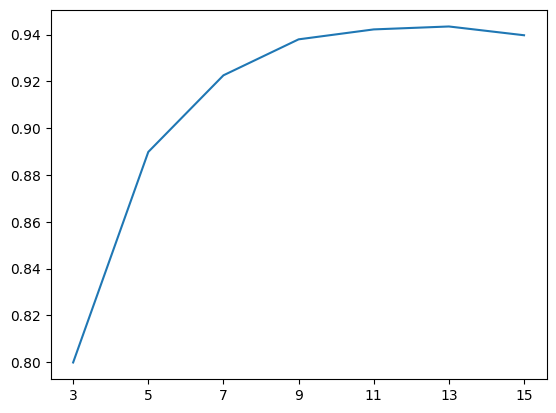

In [37]:
from sklearn.model_selection import KFold
from tqdm import tqdm
import matplotlib.pyplot as plt

kf = KFold(n_splits=5, shuffle=True)
accs = []

for depth in tqdm(range(3,16,2)):
    fold_accs = []

    for train_idx, test_idx in kf.split(data):

        train_data = data.iloc[train_idx]
        test_data = data.iloc[test_idx]

        tree = DecisionTree(max_depth=depth)
        tree.fit(train_data)

        X_test = test_data.iloc[:, :-1]
        y_test = test_data.iloc[:, -1]

        predictions = tree.predict(X_test)

        acc = np.mean(predictions == y_test)
        fold_accs.append(acc)

    accs.append(np.mean(fold_accs))


plt.plot(range(3,16,2), accs)
plt.xticks(range(3,16,2))
plt.show()

Use that depth and print the test score. Is it better generalizer than the first one?

What do you conclude about the tuning proccess using validation? (answer to yourselves).


In [39]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(data, test_size=0.2, random_state=42)

In [40]:
best_depth = 11

tree = DecisionTree(max_depth=best_depth)
tree.fit(train)

X_test = test.iloc[:, :-1]
y_test = test.iloc[:, -1]

predictions = tree.predict(X_test)

acc = np.mean(predictions == y_test)

print(f"Test accuracy is {acc}")

Test accuracy is 0.935


The second solution will make a mechanism called "early stopping". Early stopping suggests taking at each step the train and validation error, check the gap between them. Once the gap comes too large, stop. This is based directly upon the bias-variance tradeoff (overfitting vs underfitting), as discussed in class.

However, implementing this live in a run requires complex modification. Hence:
1. Run from max_depth=1,...,max_depth=21.
2. Check the gap between validation and train <u>errors</u>.
3. Use patience=2, meaning only after two consecutive times getting a rising gap, stop the loop and print the best depth found.
4. Look at the graph of train and val errors as function of the depth.


depth 1 training error 0.34125000000000005 val error 0.33375 gap -0.007500000000000062
depth 2 training error 0.22921875000000003 val error 0.21250000000000002 gap -0.016718750000000004
depth 3 training error 0.19843750000000004 val error 0.18312499999999998 gap -0.015312500000000062
depth 4 training error 0.13953125 val error 0.14 gap 0.00046875000000001776
depth 5 training error 0.10406249999999995 val error 0.09937499999999999 gap -0.004687499999999956
depth 6 training error 0.08437499999999998 val error 0.09312500000000001 gap 0.008750000000000036
depth 7 training error 0.061718750000000044 val error 0.08062499999999995 gap 0.018906249999999902
Early stopping at depth 7


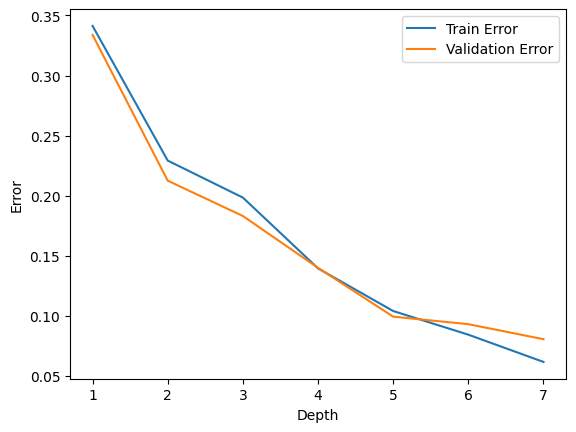

Best depth = 5


In [43]:
train_errors = []
val_errors = []
gaps = []

best_depth = 1
rising_count = 0

for depth in range(1, 22):

    tree = DecisionTree(max_depth=depth)
    tree.fit(train)

    X_train = train.iloc[:, :-1]
    y_train = train.iloc[:, -1]
    train_predictions = tree.predict(X_train)
    train_error = 1 - np.mean(train_predictions == y_train)

    X_val = test.iloc[:, :-1]
    y_val = test.iloc[:, -1]
    val_predictions = tree.predict(X_val)
    val_error = 1 - np.mean(val_predictions == y_val)

    train_errors.append(train_error)
    val_errors.append(val_error)

    gap = val_error - train_error
    gaps.append(gap)

    print("depth",depth,"training error", train_error,"val error", val_error,"gap",gap)

    if len(gaps) >= 2 and gap > 0:
        if gaps[-1] > gaps[-2]:
            rising_count += 1
        else:
            rising_count = 0
    else:
        rising_count = 0

    if rising_count >= 2:
       print(f"Early stopping at depth {depth}")
       best_depth = depth - 2
       break

depths = range(1, len(train_errors) + 1)

plt.plot(depths, train_errors, label="Train Error")
plt.plot(depths, val_errors, label="Validation Error")
plt.xlabel("Depth")
plt.ylabel("Error")
plt.legend()
plt.show()

print("Best depth =", best_depth)

Questions:
1. Justify the early stopping you got programically by looking at the graph.
2. Use bias / variance terms to justify the graph curves.
3. In this questions, you have used three methods to find the best depth for the tree. In an utopic world, where waiting time is a concern, how would you tune the best hyperparameters?

<font color='red'>
1.we notice that for values 1-4 both the train error an the validation error decrease , at depth 5 we got the smallest gap between test the validation error and the training error  so the best depth is 5 , starting from depth 6 the training error keeps decreasing while the validation error stops improving which means that the gap increases (overfitting), since the gap increases for 2 consecutive depths , the algoritm will stop early at depth 7 (after 2 iterations)
</font>


<font color='red'>

2.for small depths the tree is simple(high bias) so we didnt see enough examples ,therfore the training error and the test error is large which means the model underfits the data , when the depth increases we have more examples so the both errors will decrease then we got a lower bias , when the depth is bigger than the optimal depth the model become more complex and start fitting noise, therfore the test error increase and the training error keep decreasing which means there is an overfitting and high variance.
</font>

<font color='red'>

3.if waiting time is a concern , i would use early sttoping ,because both cross validiation and train/test split require more time to training the model on contrary to the early sttoping that stops when there is an overfitting ,therfore the running time is low.
</font>


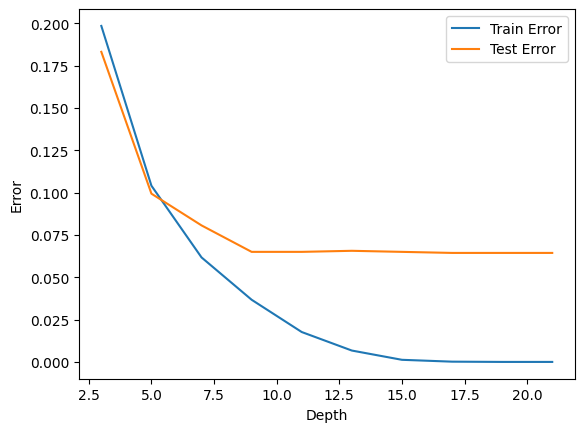

In [ ]:
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np

train, test = train_test_split(data, test_size=0.2, random_state=42)

train_err = []
test_err = []

depths = range(3, 22, 2)

for depth in depths:

    tree = DecisionTree(max_depth=depth)
    tree.fit(train)

    # Train error
    X_train = train.iloc[:, :-1]
    y_train = train.iloc[:, -1]

    train_predictions = tree.predict(X_train)
    train_accuracy = np.mean(train_predictions == y_train)
    train_error = 1 - train_accuracy

    train_err.append(train_error)

    # Test error
    X_test = test.iloc[:, :-1]
    y_test = test.iloc[:, -1]

    test_predictions = tree.predict(X_test)
    test_accuracy = np.mean(test_predictions == y_test)
    test_error = 1 - test_accuracy

    test_err.append(test_error)

plt.plot(depths, train_err, label='Train Error')
plt.plot(depths, test_err, label='Test Error')
plt.xlabel('Depth')
plt.ylabel('Error')
plt.legend()
plt.show()